<a href="https://colab.research.google.com/github/claragarciaperez/Open_Quantum_Systems_RI/blob/main/qiskit_relaxation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install qiskit[visualization]
!pip install qiskit-aer
!pip install qiskit-ibm-runtime
!pip install pylatexenc


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 32.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 51.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 66.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.9/122.9 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.3/113.3 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.0

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import transpile, QuantumCircuit
from qiskit_aer import AerSimulator
import qiskit.quantum_info as qi
from qiskit.visualization import plot_histogram
from qiskit_ibm_runtime import QiskitRuntimeService
from google.colab import drive
from qiskit_aer.noise import (
    NoiseModel,
    QuantumError,
    ReadoutError,
    depolarizing_error,
    pauli_error,
    thermal_relaxation_error,
)
drive.mount("/content/drive")


Mounted at /content/drive


# Parametes

In [3]:
Gamma = 0.25
delta_t = 0.5
g = np.sqrt(Gamma/delta_t)
omega = 1
N = int(30/delta_t)
nshots = 1024


# Load results from Linblad equation

In [4]:
file_path = (
    '/content/drive/MyDrive/'
    'cont_solution_dt_0.5_g_0.71_omegas_1.txt'
)

data_cont = np.loadtxt(file_path, comments='#')

t_cont = data_cont[:, 0]
sx_cont = data_cont[:, 1]
sy_cont = data_cont[:, 2]
sz_cont = data_cont[:, 3]

# Refresh Ancilla

### Noise - flip

In [30]:
def sz_2_circuit(simulator_aer_noise):
  sz_2_noiseflip1 = []
  for niter in range(0,N+1):
      qc = QuantumCircuit(2,1)
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      for i in range(0,niter):
          qc.rxx(g*delta_t,0,1)
          qc.ryy(g*delta_t,0,1)
          qc.rz(-omega*delta_t,0)
          qc.reset(1)
      qc.measure(0,0)
      transpiled_qc = transpile(
      qc,
      backend=simulator_aer_noise,
      optimization_level=3
  )
      job = simulator_aer_noise.run(transpiled_qc,shots = nshots)
      #print(transpiled_qc.count_ops())
      results = job.result().get_counts()
      valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
      sz_2_noiseflip1.append(-valor)
  return sz_2_noiseflip1

In [31]:
def sx_2_circuit(simulator_aer_noise):
  sx_2_noiseflip1 = []
  for niter in range(0,N+1):
      qc = QuantumCircuit(2,1)
      qc.qubits
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      for i in range(0,niter):
          qc.rxx(g*delta_t,0,1)
          qc.ryy(g*delta_t,0,1)
          qc.rz(-omega*delta_t,0)
          qc.reset(1)
      qc.h(0)
      qc.measure(0,0)

      transpiled_qc = transpile(
      qc,
      backend=simulator_aer_noise,
      optimization_level=3
  )
      job = simulator_aer_noise.run(transpiled_qc,shots = nshots)




      results = job.result().get_counts()
      valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
      sx_2_noiseflip1.append(valor)
  return sx_2_noiseflip1

In [32]:
def sy_2_circuit(simulator_aer_noise):
  sy_2_noiseflip1 = []
  for niter in range(0,N+1):
      qc = QuantumCircuit(2,1)
      qc.qubits
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      for i in range(0,niter):
          qc.rxx(g*delta_t,0,1)
          qc.ryy(g*delta_t,0,1)
          qc.rz(-omega*delta_t,0)
          qc.reset(1)
      qc.sdg(0)
      qc.h(0)
      qc.measure(0,0)

      transpiled_qc = transpile(
      qc,
      backend=simulator_aer_noise,
      optimization_level=3
  )
      job = simulator_aer_noise.run(transpiled_qc,shots = nshots)
      #print(transpiled_qc.count_ops())

      results = job.result().get_counts()
      valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
      sy_2_noiseflip1.append(-valor)
  return sy_2_noiseflip1

## Plot and save data

### Different T1,T2

> Añadir blockquote



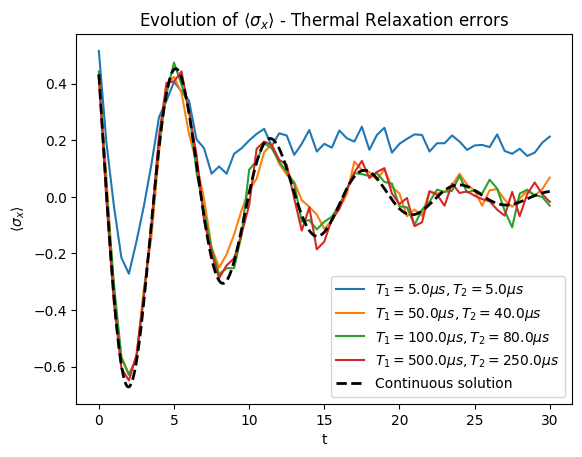

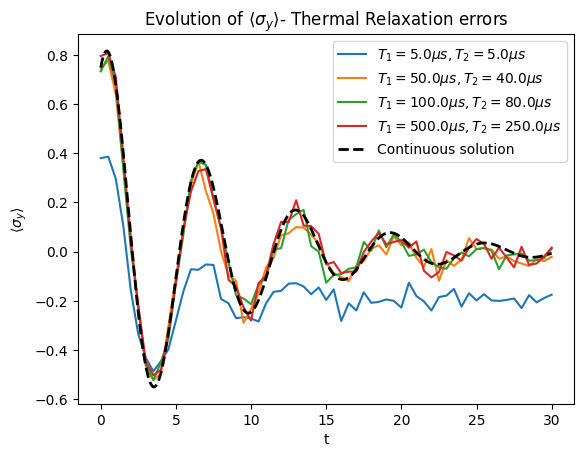

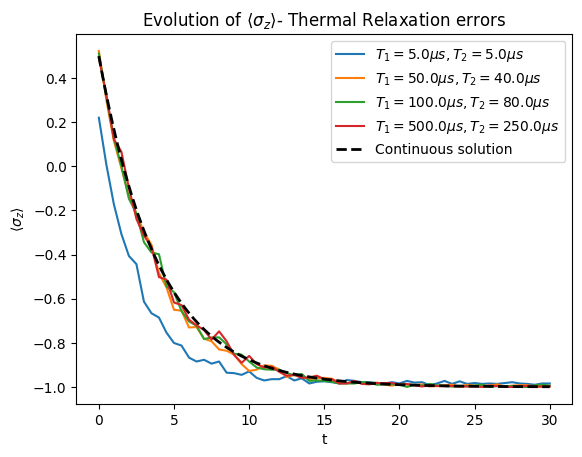

In [40]:
simualtor_aer = AerSimulator()

time = np.arange(N+1) * delta_t



fig_x, ax_x = plt.subplots()
fig_y, ax_y = plt.subplots()
fig_z, ax_z = plt.subplots()

#Times have to be introduced in nanoseconds

time_gate1 = 50
time_gate2 = 100

time_reset = 1000
time_measure = 1000

list_T1_T2= [[5e3,5e3], [50e3,40e3], [100e3,80e3], [500e3,250e3],]

for T1,T2 in list_T1_T2:

  errors_reset = thermal_relaxation_error(T1, T2, time_reset)

  errors_measure = thermal_relaxation_error(T1, T2, time_measure)

  errors_gate1 = thermal_relaxation_error(T1, T2, time_gate1)
  errors_gate2 = thermal_relaxation_error(T1, T2, time_gate2).expand( thermal_relaxation_error(T1, T2, time_gate2))

  noise_thermal = NoiseModel()
  noise_thermal.add_all_qubit_quantum_error(errors_reset, "reset")
  noise_thermal.add_all_qubit_quantum_error(errors_measure, "measure")
  noise_thermal.add_all_qubit_quantum_error(errors_gate1, ["ry", "rz","sx"])
  noise_thermal.add_all_qubit_quantum_error(errors_gate2, ["rxx","ryy"])

  simulator_aer_noise = AerSimulator(noise_model=noise_thermal)

  sx_2 = sx_2_circuit(simulator_aer_noise)
  sy_2 = sy_2_circuit(simulator_aer_noise)
  sz_2= sz_2_circuit(simulator_aer_noise)

  datos = np.column_stack((time, sx_2, sy_2, sz_2))

  np.savetxt(
  f"/content/drive/MyDrive/qiskit_noisethermal_sxsysz_ns1024_T1_{T1/1000}_T2_{T2/1000}.txt",
  datos,
  header="t sx sy sz",
  fmt="%.10f"
  )

  ax_x.plot(time, sx_2, label=rf'$T_1={T1/1000} \mu s, T_2 = {T2/1000} \mu s$')
  ax_y.plot(time, sy_2, label=rf'$T_1={T1/1000} \mu s, T_2 = {T2/1000} \mu s$')
  ax_z.plot(time, sz_2, label=rf'$T_1={T1/1000} \mu s, T_2 = {T2/1000} \mu s$')

ax_x.plot(
    t_cont, sx_cont,
    color='black', linestyle='--', linewidth=2,
    label='Continuous solution'
)

ax_y.plot(
    t_cont, sy_cont,
    color='black', linestyle='--', linewidth=2,
    label='Continuous solution'
)

ax_z.plot(
    t_cont, sz_cont,
    color='black', linestyle='--', linewidth=2,
    label='Continuous solution'
)
# Configurar figura de X
ax_x.set_xlabel('t')
ax_x.set_ylabel(r'$\langle \sigma_x \rangle$')
ax_x.set_title(r'Evolution of $\langle \sigma_x \rangle$ - Thermal Relaxation errors')
ax_x.legend()

# Configurar figura de Y
ax_y.set_xlabel('t')
ax_y.set_ylabel(r'$\langle \sigma_y \rangle$')
ax_y.set_title(r'Evolution of $\langle \sigma_y \rangle$- Thermal Relaxation errors')
ax_y.legend()

# Configurar figura de Z
ax_z.set_xlabel('t')
ax_z.set_ylabel(r'$\langle \sigma_z \rangle$')
ax_z.set_title(r'Evolution of $\langle \sigma_z \rangle$- Thermal Relaxation errors')
ax_z.legend()

plt.show()


### fez T1, T2

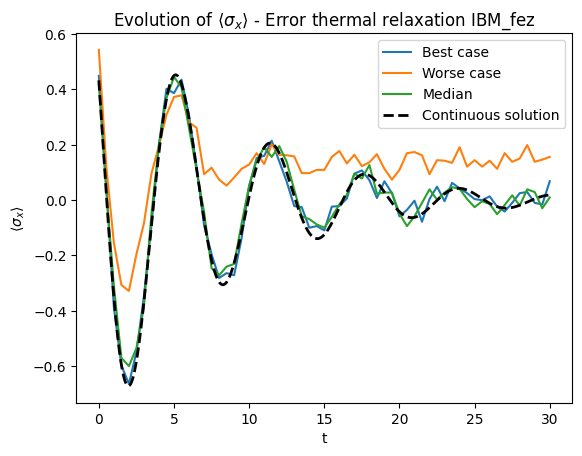

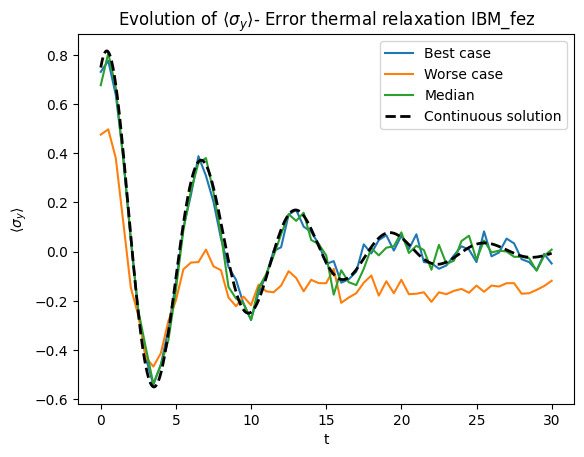

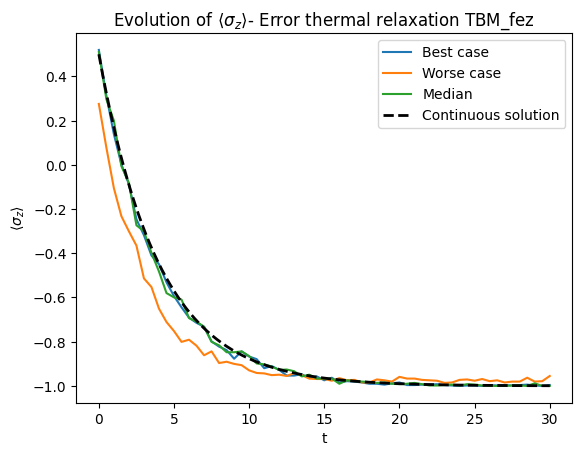

In [39]:
simualtor_aer = AerSimulator()

time = np.arange(N+1) * delta_t

time_gate1 = 50
time_gate2 = 100

time_reset = 1000
time_measure = 1000


fig_x, ax_x = plt.subplots()
fig_y, ax_y = plt.subplots()
fig_z, ax_z = plt.subplots()

T1_best= 299.21e3
T1_worst = 6.74e3
T1_median = 137.84e3

T2_best= 259.54e3
T2_worst = 4.3e3
T2_median = 95.19e3

for T1,T2 in [[T1_best,T2_best],[T1_worst,T2_worst],[T1_median,T2_median]]:
  errors_reset = thermal_relaxation_error(T1, T2, time_reset)

  errors_measure = thermal_relaxation_error(T1, T2, time_measure)

  errors_gate1 = thermal_relaxation_error(T1, T2, time_gate1)
  errors_gate2 = thermal_relaxation_error(T1, T2, time_gate2).expand( thermal_relaxation_error(T1, T2, time_gate2))

  noise_thermal = NoiseModel()
  noise_thermal.add_all_qubit_quantum_error(errors_reset, "reset")
  noise_thermal.add_all_qubit_quantum_error(errors_measure, "measure")
  noise_thermal.add_all_qubit_quantum_error(errors_gate1, ["ry", "rz","sx"])
  noise_thermal.add_all_qubit_quantum_error(errors_gate2, ["rxx","ryy"])

  simulator_aer_noise = AerSimulator(noise_model=noise_thermal)

  sx_2 = sx_2_circuit(simulator_aer_noise)
  sy_2 = sy_2_circuit(simulator_aer_noise)
  sz_2= sz_2_circuit(simulator_aer_noise)

  datos = np.column_stack((time, sx_2, sy_2, sz_2))

  if [T1,T2] == [T1_worst,T2_worst]:
    np.savetxt(
      f"/content/drive/MyDrive/qiskit_noisethermal_sxsysz_ns1024_fezworstcase.txt",
      datos,
      header="t sx sy sz",
      fmt="%.10f"
    )

    ax_x.plot(time, sx_2, label=rf'Worse case')
    ax_y.plot(time, sy_2, label=rf'Worse case')
    ax_z.plot(time, sz_2, label=rf'Worse case')

  if [T1,T2] == [T1_best,T2_best]:
    np.savetxt(
      f"/content/drive/MyDrive/qiskit_noisethermal_sxsysz_ns1024_fezbestcase.txt",
      datos,
      header="t sx sy sz",
      fmt="%.10f"
    )

    ax_x.plot(time, sx_2, label=rf'Best case')
    ax_y.plot(time, sy_2, label=rf'Best case')
    ax_z.plot(time, sz_2, label=rf'Best case')

  if [T1,T2] == [T1_median,T2_median]:
    np.savetxt(
      f"/content/drive/MyDrive/qiskit_noisethermal_sxsysz_ns1024_fezmedian.txt",
      datos,
      header="t sx sy sz",
      fmt="%.10f"
    )

    ax_x.plot(time, sx_2, label=rf'Median')
    ax_y.plot(time, sy_2, label=rf'Median')
    ax_z.plot(time, sz_2, label=rf'Median')


ax_x.plot(
    t_cont, sx_cont,
    color='black', linestyle='--', linewidth=2,
    label='Continuous solution'
)

ax_y.plot(
    t_cont, sy_cont,
    color='black', linestyle='--', linewidth=2,
    label='Continuous solution'
)

ax_z.plot(
    t_cont, sz_cont,
    color='black', linestyle='--', linewidth=2,
    label='Continuous solution'
)
# Configurar figura de X
ax_x.set_xlabel('t')
ax_x.set_ylabel(r'$\langle \sigma_x \rangle$')
ax_x.set_title(r'Evolution of $\langle \sigma_x \rangle$ - Error thermal relaxation IBM_fez')
ax_x.legend()

# Configurar figura de Y
ax_y.set_xlabel('t')
ax_y.set_ylabel(r'$\langle \sigma_y \rangle$')
ax_y.set_title(r'Evolution of $\langle \sigma_y \rangle$- Error thermal relaxation IBM_fez')
ax_y.legend()

# Configurar figura de Z
ax_z.set_xlabel('t')
ax_z.set_ylabel(r'$\langle \sigma_z \rangle$')
ax_z.set_title(r'Evolution of $\langle \sigma_z \rangle$- Error thermal relaxation TBM_fez')
ax_z.legend()

plt.show()


### No noise

In [ ]:
def sz_2_nonoise_circuit(simulator_aer):
  sz_2_nonoise = []
  for niter in range(0,N+1):
      qc = QuantumCircuit(2,1)
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      for i in range(0,niter):
          qc.rxx(g*delta_t,0,1)
          qc.ryy(g*delta_t,0,1)
          qc.rz(-omega*delta_t,0)
          qc.reset(1)
      qc.measure(0,0)

      job = simualtor_aer.run(qc,shots = nshots)
      results = job.result().get_counts()
      valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
      sz_2_nonoise.append(-valor)
  return sz_2_nonoise

In [ ]:
def sx_2_nonoise_circuit(simulator_aer):
  sx_2_nonoise = []
  for niter in range(0,N+1):
      qc = QuantumCircuit(2,1)
      qc.qubits
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      for i in range(0,niter):
          qc.rxx(g*delta_t,0,1)
          qc.ryy(g*delta_t,0,1)
          qc.rz(-omega*delta_t,0)
          qc.reset(1)
      qc.h(0)
      qc.measure(0,0)

      job = simulator_aer.run(qc,shots = nshots)


      results = job.result().get_counts()
      valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
      sx_2_nonoise.append(valor)
  return sx_2_nonoise

In [ ]:
def sy_2_nonoise_circuit(simulator_aer):
  sy_2_nonoise = []
  for niter in range(0,N+1):
      qc = QuantumCircuit(2,1)
      qc.qubits
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      for i in range(0,niter):
          qc.rxx(g*delta_t,0,1)
          qc.ryy(g*delta_t,0,1)
          qc.rz(-omega*delta_t,0)
          qc.reset(1)
      qc.sdg(0)
      qc.h(0)
      qc.measure(0,0)

      job = simulator_aer.run(qc,shots = nshots)

      results = job.result().get_counts()
      valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
      sy_2_nonoise.append(-valor)
  return sy_2_nonoise

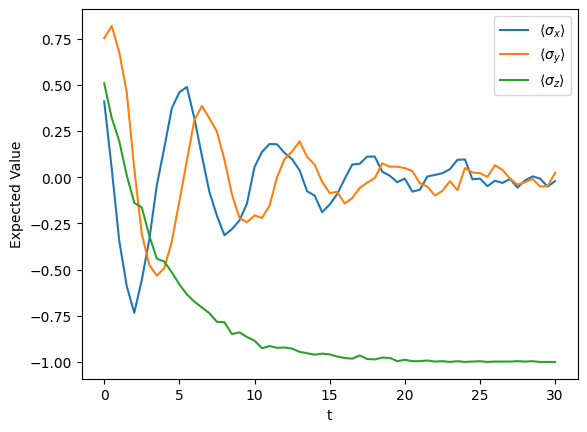

In [ ]:
simulator_aer = AerSimulator()
sx_2_nonoise = sx_2_nonoise_circuit(simulator_aer)
sy_2_nonoise= sy_2_nonoise_circuit(simulator_aer)
sz_2_nonoise= sz_2_nonoise_circuit(simulator_aer)

time = np.arange(N+1) * delta_t
plt.plot(time, sx_2_nonoise,label=rf'$\langle \sigma_x\rangle$')
plt.plot(time, sy_2_nonoise,label=rf'$\langle \sigma_y\rangle$')
plt.plot(time, sz_2_nonoise,label=rf'$\langle \sigma_z\rangle$')

plt.xlabel('t')
plt.ylabel('Expected Value')
plt.legend()


In [ ]:

datos = np.column_stack((time, sx_2, sy_2, sz_2))

np.savetxt(
    "/content/drive/MyDrive/qiskit2_nonoise_sxsysz_ns4096.txt",
    datos,
    header="t sx sy sz",
    fmt="%.10f"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
